# Quora Question Pairs: Siamese BiLSTM e Features Manuais

Este notebook resolve o problema **Quora Question Pairs**, cujo objetivo é classificar se duas perguntas possuem o mesmo significado. A tarefa é de Processamento de Linguagem Natural com dados textuais não estruturados.

A solução foi organizada em dois experimentos:

- **Modelo A:** rede Siamese BiLSTM com pesos compartilhados.
- **Modelo B:** Siamese BiLSTM combinada com atributos manuais de similaridade textual.

A métrica oficial da competição do Kaggle é **Log Loss**, mas também serão reportadas Accuracy, Precision, Recall, F1 e ROC AUC para uma análise mais completa.

## 1. Introdução

O Quora recebe muitas perguntas semanticamente equivalentes escritas de formas diferentes. Detectar perguntas duplicadas ajuda a consolidar respostas, melhorar a busca e reduzir conteúdo repetido.

Do ponto de vista de Machine Learning, o problema é uma classificação binária:

- `1`: as perguntas são duplicadas, isto é, têm essencialmente o mesmo significado.
- `0`: as perguntas não são duplicadas.

O desafio está no fato de que duas perguntas podem compartilhar muitas palavras e ainda assim ter intenções diferentes, ou usar palavras diferentes para expressar a mesma intenção. Por isso, combinamos uma rede neural recorrente, capaz de aprender representações semânticas, com atributos manuais que capturam sinais lexicais diretos.

## 2. Importação das bibliotecas

As bibliotecas utilizadas cobrem manipulação de dados, visualização, pré-processamento textual, treinamento de redes neurais e avaliação dos modelos.

In [4]:
import os
import re
import random
from typing import List, Optional, Tuple
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    roc_curve,
)
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Lambda,
    Concatenate,
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 3. Configuração de reprodutibilidade

Para tornar os experimentos reproduzíveis, fixamos as sementes aleatórias de Python, NumPy e TensorFlow. Também centralizamos os principais hiperparâmetros em um dicionário de configuração.

O dataset original é relativamente grande. A variável `TRAIN_SAMPLE_SIZE` permite executar o notebook mais rapidamente em ambientes com recursos limitados. Para usar todo o treino, defina `TRAIN_SAMPLE_SIZE = None`.

In [5]:
SEED = 42

def set_global_seed(seed: int = 42) -> None:
    """Fixa sementes aleatórias para aumentar a reprodutibilidade do experimento."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_global_seed(SEED)

CONFIG = {
    "data_dir": Path("datasets"),
    "train_sample_size": 120_000,  # use None para treinar com todo o train.csv
    "test_sample_size": None,      # mantenha None para gerar submission completa
    "validation_size": 0.20,
    "max_words": 60_000,
    "max_sequence_length": 40,
    "embedding_dim": 128,
    "lstm_units": 64,
    "batch_size": 512,
    "epochs": 8,
    "learning_rate": 1e-3,
    "tfidf_max_features": 50_000,
}

CONFIG

{'data_dir': PosixPath('datasets'),
 'train_sample_size': 120000,
 'test_sample_size': None,
 'validation_size': 0.2,
 'max_words': 60000,
 'max_sequence_length': 40,
 'embedding_dim': 128,
 'lstm_units': 64,
 'batch_size': 512,
 'epochs': 8,
 'learning_rate': 0.001,
 'tfidf_max_features': 50000}

## 4. Leitura do dataset

Os arquivos esperados são:

- `datasets/train.csv`: pares de perguntas rotulados.
- `datasets/test.csv`: pares de perguntas sem rótulo.
- `datasets/sample_submission.csv`: formato esperado da submissão.

A leitura é encapsulada em uma função para facilitar reuso e permitir amostragem controlada.

In [6]:
def load_quora_data(data_dir: Path, train_sample_size: Optional[int] = None, test_sample_size: Optional[int] = None) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Carrega os arquivos da competição e aplica amostragem opcional.

    A amostragem é útil para desenvolvimento local. Quando o objetivo for gerar a
    submissão final, recomenda-se usar todo o treino e todo o teste.
    """
    train_path = data_dir / "train.csv"
    test_path = data_dir / "test.csv"
    sample_submission_path = data_dir / "sample_submission.csv"

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    sample_submission_df = pd.read_csv(sample_submission_path)

    if train_sample_size is not None and train_sample_size < len(train_df):
        train_df = train_df.sample(train_sample_size, random_state=SEED).reset_index(drop=True)

    if test_sample_size is not None and test_sample_size < len(test_df):
        test_df = test_df.sample(test_sample_size, random_state=SEED).reset_index(drop=True)

    return train_df, test_df, sample_submission_df


train_df, test_df, sample_submission_df = load_quora_data(
    CONFIG["data_dir"],
    CONFIG["train_sample_size"],
    CONFIG["test_sample_size"],
)

print(f"Treino: {train_df.shape}")
print(f"Teste:  {test_df.shape}")
display(train_df.head())
display(test_df.head())

Treino: (120000, 6)
Teste:  (3563475, 3)


,id,qid1,qid2,question1,question2,is_duplicate
0,8067,15738,15739,How do I play Pokémon GO in Korea?,How do I play Pokémon GO in China?,0
1,368101,12736,104117,What are some of the best side dishes for crab...,What are some good side dishes for buffalo chi...,0
2,70497,121486,121487,Which is more advisable and better material fo...,What is the best server setup for buddypress?,0
3,226567,254474,258192,How do I improve logical programming skills?,How can I improve my logical skills for progra...,1
4,73186,48103,3062,How close we are to see 3rd world war?,How close is a World War III?,1


,test_id,question1,question2
0,0,How does the Surface Pro himself 4 compare wit...,Why did Microsoft choose core m3 and not core ...
1,1,Should I have a hair transplant at age 24? How...,How much cost does hair transplant require?
2,2,What but is the best way to send money from Ch...,What you send money to China?
3,3,Which food not emulsifiers?,What foods fibre?
4,4,"How ""aberystwyth"" start reading?",How their can I start reading?


## 5. Análise exploratória

A exploração inicial verifica distribuição das classes, valores ausentes e tamanho das perguntas. Essas informações ajudam a definir o pré-processamento e a arquitetura da rede.

In [7]:
def add_length_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Adiciona colunas com quantidade de caracteres e palavras em cada pergunta."""
    df = df.copy()
    for col in ["question1", "question2"]:
        df[f"{col}_num_chars"] = df[col].fillna("").astype(str).str.len()
        df[f"{col}_num_words"] = df[col].fillna("").astype(str).str.split().str.len()
    return df


eda_df = add_length_columns(train_df)

print("Valores nulos no treino:")
display(train_df.isna().sum())

print("Distribuição da variável alvo:")
display(train_df["is_duplicate"].value_counts(normalize=True).rename("proportion"))

Valores nulos no treino:


id              0
qid1            0
qid2            0
question1       0
question2       1
is_duplicate    0
dtype: int64

Distribuição da variável alvo:


is_duplicate
0    0.62955
1    0.37045
Name: proportion, dtype: float64

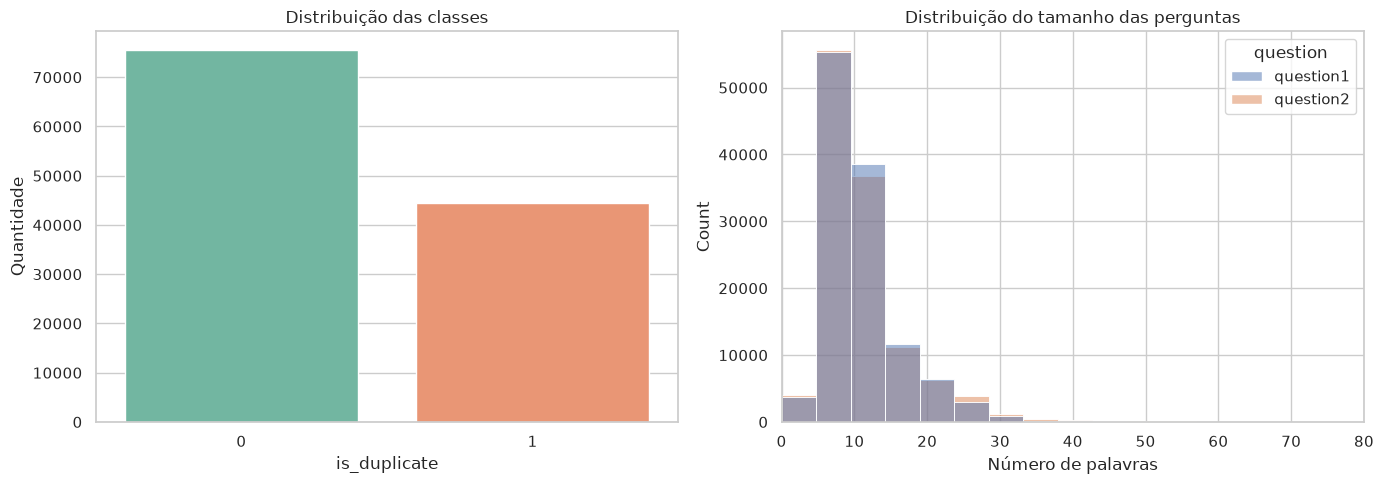

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train_df, x="is_duplicate", ax=axes[0], palette="Set2")
axes[0].set_title("Distribuição das classes")
axes[0].set_xlabel("is_duplicate")
axes[0].set_ylabel("Quantidade")

lengths = pd.concat([
    eda_df[["question1_num_words"]].rename(columns={"question1_num_words": "num_words"}).assign(question="question1"),
    eda_df[["question2_num_words"]].rename(columns={"question2_num_words": "num_words"}).assign(question="question2"),
])
sns.histplot(data=lengths, x="num_words", hue="question", bins=50, kde=False, ax=axes[1])
axes[1].set_title("Distribuição do tamanho das perguntas")
axes[1].set_xlabel("Número de palavras")
axes[1].set_xlim(0, 80)

plt.tight_layout()
plt.show()

## 6. Pré-processamento

As etapas implementadas são:

- **Tratamento de valores nulos:** substituição por string vazia, evitando erros em operações de texto.
- **Lowercase:** reduz variações artificiais entre palavras iguais com capitalização diferente.
- **Remoção de caracteres especiais:** mantém letras, números e espaços, reduzindo ruído textual.
- **Tokenização:** converte textos em sequências de inteiros.
- **Padding:** padroniza o tamanho das sequências para entrada na rede neural.
- **Divisão treino/validação:** separa uma parte rotulada para avaliação fora do treinamento.

In [9]:
def clean_text(text: object) -> str:
    """Limpa uma pergunta aplicando nulos, lowercase e remoção de caracteres especiais."""
    text = "" if pd.isna(text) else str(text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def preprocess_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """Cria versões limpas das colunas question1 e question2."""
    df = df.copy()
    df["question1_clean"] = df["question1"].apply(clean_text)
    df["question2_clean"] = df["question2"].apply(clean_text)
    return df


train_clean = preprocess_dataframe(train_df)
test_clean = preprocess_dataframe(test_df)

display(train_clean[["question1", "question1_clean", "question2", "question2_clean", "is_duplicate"]].head())

,question1,question1_clean,question2,question2_clean,is_duplicate
0,How do I play Pokémon GO in Korea?,how do i play pok mon go in korea,How do I play Pokémon GO in China?,how do i play pok mon go in china,0
1,What are some of the best side dishes for crab...,what are some of the best side dishes for crab...,What are some good side dishes for buffalo chi...,what are some good side dishes for buffalo chi...,0
2,Which is more advisable and better material fo...,which is more advisable and better material fo...,What is the best server setup for buddypress?,what is the best server setup for buddypress,0
3,How do I improve logical programming skills?,how do i improve logical programming skills,How can I improve my logical skills for progra...,how can i improve my logical skills for progra...,1
4,How close we are to see 3rd world war?,how close we are to see 3rd world war,How close is a World War III?,how close is a world war iii,1


In [10]:
train_part, valid_part = train_test_split(
    train_clean,
    test_size=CONFIG["validation_size"],
    random_state=SEED,
    stratify=train_clean["is_duplicate"],
)

train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)

print(f"Treino interno: {train_part.shape}")
print(f"Validação:      {valid_part.shape}")

Treino interno: (96000, 8)
Validação:      (24000, 8)


In [11]:
def fit_tokenizer(train_data: pd.DataFrame, max_words: int) -> Tokenizer:
    """Ajusta o tokenizador apenas nos textos do conjunto de treino interno."""
    tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
    texts = pd.concat([train_data["question1_clean"], train_data["question2_clean"]]).tolist()
    tokenizer.fit_on_texts(texts)
    return tokenizer


def texts_to_padded_sequences(tokenizer: Tokenizer, texts: pd.Series, max_length: int) -> np.ndarray:
    """Converte textos limpos para sequências tokenizadas com padding pós-texto."""
    sequences = tokenizer.texts_to_sequences(texts.tolist())
    return pad_sequences(sequences, maxlen=max_length, padding="post", truncating="post")


def build_sequence_inputs(df: pd.DataFrame, tokenizer: Tokenizer, max_length: int) -> Tuple[np.ndarray, np.ndarray]:
    """Gera os dois arrays de entrada da arquitetura Siamese."""
    q1 = texts_to_padded_sequences(tokenizer, df["question1_clean"], max_length)
    q2 = texts_to_padded_sequences(tokenizer, df["question2_clean"], max_length)
    return q1, q2


tokenizer = fit_tokenizer(train_part, CONFIG["max_words"])
vocab_size = min(CONFIG["max_words"], len(tokenizer.word_index) + 1)

X_train_q1, X_train_q2 = build_sequence_inputs(train_part, tokenizer, CONFIG["max_sequence_length"])
X_valid_q1, X_valid_q2 = build_sequence_inputs(valid_part, tokenizer, CONFIG["max_sequence_length"])
X_test_q1, X_test_q2 = build_sequence_inputs(test_clean, tokenizer, CONFIG["max_sequence_length"])

y_train = train_part["is_duplicate"].astype(int).values
y_valid = valid_part["is_duplicate"].astype(int).values

print(f"Vocabulário usado: {vocab_size}")
print(f"Formato q1 treino: {X_train_q1.shape}")
print(f"Formato q2 treino: {X_train_q2.shape}")

Vocabulário usado: 44953
Formato q1 treino: (96000, 40)
Formato q2 treino: (96000, 40)


## 7. Engenharia de atributos manuais

Além das sequências de tokens, o Modelo B usa atributos desenhados para capturar sinais simples, mas informativos:

- diferença entre número de palavras;
- Jaccard Similarity entre conjuntos de palavras;
- Word Overlap normalizado;
- mesma primeira palavra;
- mesma última palavra;
- quantidade de números compartilhados;
- similaridade cosseno entre vetores TF-IDF.

Esses atributos podem melhorar a classificação porque fornecem pistas explícitas de sobreposição lexical e estrutura superficial. A BiLSTM aprende representações a partir da sequência, enquanto as features manuais destacam relações que podem ser difíceis de aprender com poucos dados ou poucas épocas.

In [12]:
def extract_numbers(text: str) -> set:
    """Extrai números presentes em uma pergunta."""
    return set(re.findall(r"\d+", text))


def jaccard_similarity(tokens1: List[str], tokens2: List[str]) -> float:
    """Calcula a similaridade de Jaccard entre dois conjuntos de tokens."""
    set1, set2 = set(tokens1), set(tokens2)
    union = set1 | set2
    if not union:
        return 0.0
    return len(set1 & set2) / len(union)


def word_overlap(tokens1: List[str], tokens2: List[str]) -> float:
    """Calcula uma taxa de sobreposição normalizada pelo menor tamanho das perguntas."""
    set1, set2 = set(tokens1), set(tokens2)
    denominator = min(len(set1), len(set2))
    if denominator == 0:
        return 0.0
    return len(set1 & set2) / denominator


def build_manual_features_without_tfidf(df: pd.DataFrame) -> pd.DataFrame:
    """Cria atributos lexicais independentes de ajuste estatístico."""
    rows = []
    for q1, q2 in zip(df["question1_clean"], df["question2_clean"]):
        tokens1 = q1.split()
        tokens2 = q2.split()
        nums1 = extract_numbers(q1)
        nums2 = extract_numbers(q2)

        rows.append({
            "word_count_diff": abs(len(tokens1) - len(tokens2)),
            "jaccard_similarity": jaccard_similarity(tokens1, tokens2),
            "word_overlap": word_overlap(tokens1, tokens2),
            "same_first_word": int(bool(tokens1 and tokens2 and tokens1[0] == tokens2[0])),
            "same_last_word": int(bool(tokens1 and tokens2 and tokens1[-1] == tokens2[-1])),
            "shared_numbers": len(nums1 & nums2),
        })

    return pd.DataFrame(rows, index=df.index)


class ManualFeatureBuilder:
    """Constrói, ajusta e transforma as features manuais usadas no Modelo B."""

    def __init__(self, tfidf_max_features: int = 50_000):
        self.tfidf = TfidfVectorizer(max_features=tfidf_max_features, ngram_range=(1, 2), min_df=2)
        self.scaler = StandardScaler()

    def fit(self, df: pd.DataFrame) -> "ManualFeatureBuilder":
        """Ajusta TF-IDF e normalizador usando apenas o treino interno."""
        corpus = pd.concat([df["question1_clean"], df["question2_clean"]]).tolist()
        self.tfidf.fit(corpus)
        features = self._build_features(df)
        self.scaler.fit(features)
        return self

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        """Transforma um dataframe em matriz numérica de features normalizadas."""
        features = self._build_features(df)
        return self.scaler.transform(features).astype("float32")

    def _build_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """Combina atributos lexicais e similaridade TF-IDF por cosseno."""
        features = build_manual_features_without_tfidf(df)

        q1_tfidf = self.tfidf.transform(df["question1_clean"])
        q2_tfidf = self.tfidf.transform(df["question2_clean"])
        cosine_similarity = q1_tfidf.multiply(q2_tfidf).sum(axis=1).A1

        features["tfidf_cosine_similarity"] = cosine_similarity
        return features


feature_builder = ManualFeatureBuilder(CONFIG["tfidf_max_features"]).fit(train_part)
X_train_features = feature_builder.transform(train_part)
X_valid_features = feature_builder.transform(valid_part)
X_test_features = feature_builder.transform(test_clean)

manual_feature_names = feature_builder._build_features(train_part.head(1)).columns.tolist()
print(manual_feature_names)
print(X_train_features.shape, X_valid_features.shape, X_test_features.shape)

['word_count_diff', 'jaccard_similarity', 'word_overlap', 'same_first_word', 'same_last_word', 'shared_numbers', 'tfidf_cosine_similarity']
(96000, 7) (24000, 7) (3563475, 7)


## 8. Modelo Baseline: Siamese BiLSTM

A arquitetura Siamese processa as duas perguntas com a **mesma sub-rede**, ou seja, com compartilhamento de pesos. Isso força o modelo a aprender uma representação comum para perguntas.

Fluxo do Modelo A:

1. cada pergunta passa por uma camada de `Embedding`;
2. as sequências são codificadas por uma `Bidirectional LSTM` compartilhada;
3. calcula-se a diferença absoluta entre os vetores das duas perguntas;
4. camadas densas produzem uma probabilidade via `sigmoid`.

A função de perda é **Binary Crossentropy**, adequada para classificação binária probabilística.

In [13]:
def create_siamese_bilstm_model(
    vocab_size: int,
    max_sequence_length: int,
    embedding_dim: int,
    lstm_units: int,
    learning_rate: float,
) -> Model:
    """Cria o Modelo A: Siamese BiLSTM com diferença absoluta entre embeddings."""
    q1_input = Input(shape=(max_sequence_length,), name="question1_input")
    q2_input = Input(shape=(max_sequence_length,), name="question2_input")

    shared_embedding = Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True,
        name="shared_embedding",
    )
    shared_encoder = Bidirectional(
        LSTM(lstm_units, dropout=0.20, recurrent_dropout=0.10),
        name="shared_bilstm",
    )

    q1_encoded = shared_encoder(shared_embedding(q1_input))
    q2_encoded = shared_encoder(shared_embedding(q2_input))

    absolute_difference = Lambda(
        lambda tensors: tf.abs(tensors[0] - tensors[1]),
        name="absolute_difference",
    )([q1_encoded, q2_encoded])

    x = Dense(128, activation="relu", name="dense_128")(absolute_difference)
    x = Dropout(0.30, name="dropout_1")(x)
    x = Dense(64, activation="relu", name="dense_64")(x)
    x = Dropout(0.20, name="dropout_2")(x)
    output = Dense(1, activation="sigmoid", name="is_duplicate")(x)

    model = Model(inputs=[q1_input, q2_input], outputs=output, name="siamese_bilstm")
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


model_a = create_siamese_bilstm_model(
    vocab_size=vocab_size,
    max_sequence_length=CONFIG["max_sequence_length"],
    embedding_dim=CONFIG["embedding_dim"],
    lstm_units=CONFIG["lstm_units"],
    learning_rate=CONFIG["learning_rate"],
)

model_a.summary()

E0000 00:00:1782678259.699255   54374 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1782678259.700239   58643 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1782678259.721639   54374 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "siamese_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ question1_input     │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ question2_input     │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_embedding    │ (None, 40, 128)   │  5,753,984 │ question1_input[… │
│ (Embedding)         │                   │            │ question2_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 40)        │          0 │ question1_input[… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 40)        │          0 │ question2_input[… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_bilstm       │ (None, 128)       │     98,816 │ shared_embedding… │
│ (Bidirectional)     │                   │            │ not_equal[0][0],  │
│                     │                   │            │ shared_embedding… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_difference │ (None, 128)       │          0 │ shared_bilstm[0]… │
│ (Lambda)            │                   │            │ shared_bilstm[1]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │     16,512 │ absolute_differe… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_64[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ is_duplicate        │ (None, 1)         │         65 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,877,633 (22.42 MB)

 Trainable params: 5,877,633 (22.42 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Modelo Proposto: Siamese BiLSTM + Features Manuais

O Modelo B mantém a mesma base Siamese BiLSTM, mas concatena as features manuais ao vetor de diferença absoluta antes das camadas densas finais.

Essa combinação é interessante porque une duas fontes de informação:

- a rede neural aprende padrões semânticos e sequenciais;
- os atributos manuais fornecem sinais explícitos de similaridade lexical, números e posição de palavras.

In [14]:
def create_siamese_bilstm_with_features_model(
    vocab_size: int,
    max_sequence_length: int,
    num_manual_features: int,
    embedding_dim: int,
    lstm_units: int,
    learning_rate: float,
) -> Model:
    """Cria o Modelo B: Siamese BiLSTM concatenada com features manuais."""
    q1_input = Input(shape=(max_sequence_length,), name="question1_input")
    q2_input = Input(shape=(max_sequence_length,), name="question2_input")
    manual_features_input = Input(shape=(num_manual_features,), name="manual_features_input")

    shared_embedding = Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True,
        name="shared_embedding",
    )
    shared_encoder = Bidirectional(
        LSTM(lstm_units, dropout=0.20, recurrent_dropout=0.10),
        name="shared_bilstm",
    )

    q1_encoded = shared_encoder(shared_embedding(q1_input))
    q2_encoded = shared_encoder(shared_embedding(q2_input))

    absolute_difference = Lambda(
        lambda tensors: tf.abs(tensors[0] - tensors[1]),
        name="absolute_difference",
    )([q1_encoded, q2_encoded])

    combined = Concatenate(name="network_plus_manual_features")([
        absolute_difference,
        manual_features_input,
    ])

    x = Dense(128, activation="relu", name="dense_128")(combined)
    x = Dropout(0.35, name="dropout_1")(x)
    x = Dense(64, activation="relu", name="dense_64")(x)
    x = Dropout(0.20, name="dropout_2")(x)
    output = Dense(1, activation="sigmoid", name="is_duplicate")(x)

    model = Model(
        inputs=[q1_input, q2_input, manual_features_input],
        outputs=output,
        name="siamese_bilstm_with_manual_features",
    )
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


model_b = create_siamese_bilstm_with_features_model(
    vocab_size=vocab_size,
    max_sequence_length=CONFIG["max_sequence_length"],
    num_manual_features=X_train_features.shape[1],
    embedding_dim=CONFIG["embedding_dim"],
    lstm_units=CONFIG["lstm_units"],
    learning_rate=CONFIG["learning_rate"],
)

model_b.summary()

Model: "siamese_bilstm_with_manual_features"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ question1_input     │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ question2_input     │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_embedding    │ (None, 40, 128)   │  5,753,984 │ question1_input[… │
│ (Embedding)         │                   │            │ question2_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 40)        │          0 │ question1_input[… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 40)        │          0 │ question2_input[… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_bilstm       │ (None, 128)       │     98,816 │ shared_embedding… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0… │
│                     │                   │            │ shared_embedding… │
│                     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_difference │ (None, 128)       │          0 │ shared_bilstm[0]… │
│ (Lambda)            │                   │            │ shared_bilstm[1]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ manual_features_in… │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ network_plus_manua… │ (None, 135)       │          0 │ absolute_differe… │
│ (Concatenate)       │                   │            │ manual_features_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │     17,408 │ network_plus_man… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_64[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ is_duplicate        │ (None, 1)         │         65 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,878,529 (22.42 MB)

 Trainable params: 5,878,529 (22.42 MB)

 Non-trainable params: 0 (0.00 B)

## 10. Treinamento

O treinamento usa `EarlyStopping` para interromper quando a validação deixa de melhorar e `ReduceLROnPlateau` para reduzir a taxa de aprendizado em platôs. As duas técnicas ajudam a controlar overfitting e estabilizar o treinamento.

In [15]:
def get_callbacks() -> List[tf.keras.callbacks.Callback]:
    """Retorna callbacks comuns aos experimentos."""
    return [
        EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5),
    ]


def train_model(
    model: Model,
    train_inputs: List[np.ndarray],
    valid_inputs: List[np.ndarray],
    y_train: np.ndarray,
    y_valid: np.ndarray,
    config: dict,
) -> tf.keras.callbacks.History:
    """Treina um modelo Keras usando os mesmos hiperparâmetros dos experimentos."""
    history = model.fit(
        train_inputs,
        y_train,
        validation_data=(valid_inputs, y_valid),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        callbacks=get_callbacks(),
        verbose=1,
    )
    return history

In [16]:
history_a = train_model(
    model=model_a,
    train_inputs=[X_train_q1, X_train_q2],
    valid_inputs=[X_valid_q1, X_valid_q2],
    y_train=y_train,
    y_valid=y_valid,
    config=CONFIG,
)

Epoch 1/8


E0000 00:00:1782678290.705126   54374 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


188/188 ━━━━━━━━━━━━━━━━━━━━ 32s 141ms/step - accuracy: 0.6604 - auc: 0.7118 - loss: 0.5936 - val_accuracy: 0.7302 - val_auc: 0.7941 - val_loss: 0.5286 - learning_rate: 0.0010
Epoch 2/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 139ms/step - accuracy: 0.7947 - auc: 0.8685 - loss: 0.4330 - val_accuracy: 0.7525 - val_auc: 0.8466 - val_loss: 0.5065 - learning_rate: 0.0010
Epoch 3/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 139ms/step - accuracy: 0.8601 - auc: 0.9284 - loss: 0.3221 - val_accuracy: 0.7613 - val_auc: 0.8573 - val_loss: 0.5228 - learning_rate: 0.0010
Epoch 4/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 138ms/step - accuracy: 0.9026 - auc: 0.9583 - loss: 0.2406 - val_accuracy: 0.7597 - val_auc: 0.8631 - val_loss: 0.5635 - learning_rate: 5.0000e-04


In [17]:
history_b = train_model(
    model=model_b,
    train_inputs=[X_train_q1, X_train_q2, X_train_features],
    valid_inputs=[X_valid_q1, X_valid_q2, X_valid_features],
    y_train=y_train,
    y_valid=y_valid,
    config=CONFIG,
)

Epoch 1/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 32s 139ms/step - accuracy: 0.7019 - auc: 0.7736 - loss: 0.5315 - val_accuracy: 0.7359 - val_auc: 0.8175 - val_loss: 0.4873 - learning_rate: 0.0010
Epoch 2/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 136ms/step - accuracy: 0.7732 - auc: 0.8577 - loss: 0.4424 - val_accuracy: 0.7923 - val_auc: 0.8762 - val_loss: 0.4179 - learning_rate: 0.0010
Epoch 3/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 136ms/step - accuracy: 0.8443 - auc: 0.9227 - loss: 0.3369 - val_accuracy: 0.8034 - val_auc: 0.8837 - val_loss: 0.4288 - learning_rate: 0.0010
Epoch 4/8
188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 136ms/step - accuracy: 0.8947 - auc: 0.9593 - loss: 0.2463 - val_accuracy: 0.8048 - val_auc: 0.8816 - val_loss: 0.4678 - learning_rate: 5.0000e-04


## 11. Curvas de treinamento

As curvas permitem verificar se os modelos estão aprendendo, se há overfitting e como a perda evolui em treino e validação.

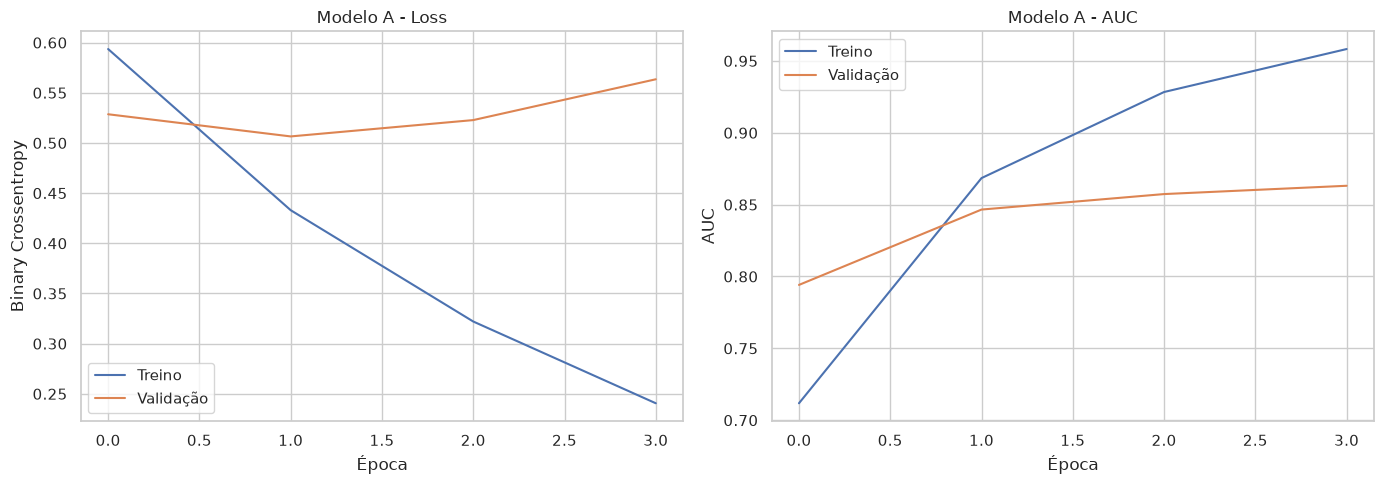

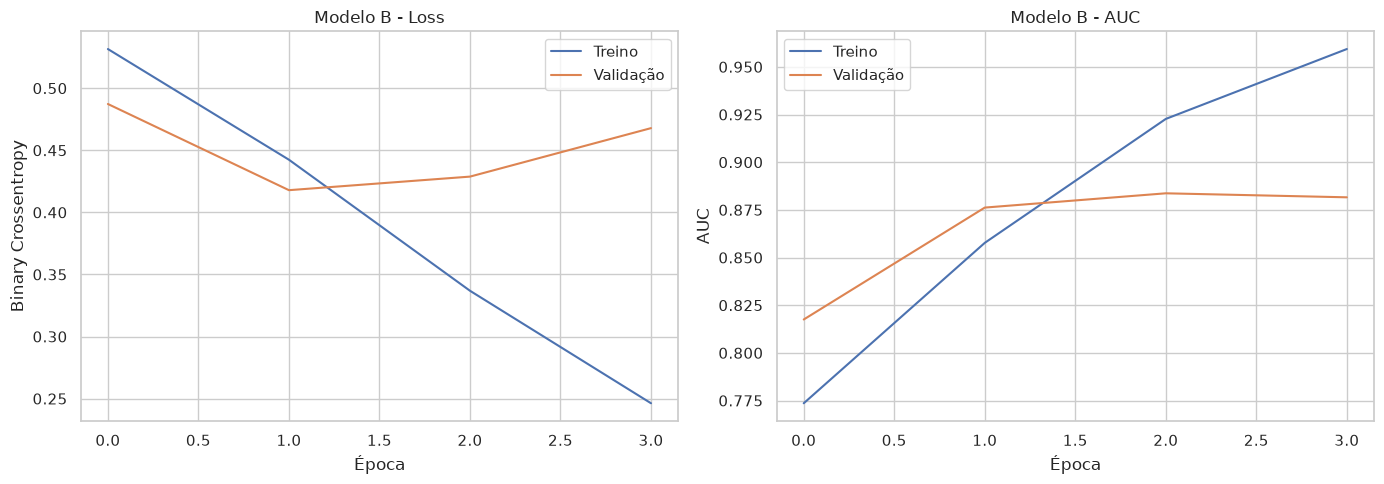

In [18]:
def plot_training_curves(history: tf.keras.callbacks.History, title: str) -> None:
    """Plota curvas de loss e AUC para treino e validação."""
    history_df = pd.DataFrame(history.history)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history_df["loss"], label="Treino")
    axes[0].plot(history_df["val_loss"], label="Validação")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Binary Crossentropy")
    axes[0].legend()

    axes[1].plot(history_df["auc"], label="Treino")
    axes[1].plot(history_df["val_auc"], label="Validação")
    axes[1].set_title(f"{title} - AUC")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("AUC")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


plot_training_curves(history_a, "Modelo A")
plot_training_curves(history_b, "Modelo B")

## 12. Avaliação

A avaliação transforma probabilidades em classes usando limiar `0.5` para Accuracy, Precision, Recall e F1. Log Loss e ROC AUC usam as probabilidades diretamente, preservando a informação de confiança do modelo.

In [20]:
def evaluate_model(model: Model, valid_inputs: List[np.ndarray], y_true: np.ndarray, model_name: str) -> dict:
    """Calcula métricas de classificação para um modelo treinado."""
    y_proba = model.predict(valid_inputs, batch_size=CONFIG["batch_size"]).ravel()
    y_proba = np.clip(y_proba, 1e-7, 1 - 1e-7)
    y_pred = (y_proba >= 0.5).astype(int)

    return {
        "modelo": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "log_loss": log_loss(y_true, y_proba),
        "y_proba": y_proba,
        "y_pred": y_pred,
    }


results_a = evaluate_model(model_a, [X_valid_q1, X_valid_q2], y_valid, "Modelo A - Siamese BiLSTM")
results_b = evaluate_model(model_b, [X_valid_q1, X_valid_q2, X_valid_features], y_valid, "Modelo B - BiLSTM + Features")

comparison_df = pd.DataFrame([results_a, results_b]).drop(columns=["y_proba", "y_pred"])
display(comparison_df.style.format({
    "accuracy": "{:.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "f1": "{:.4f}",
    "roc_auc": "{:.4f}",
    "log_loss": "{:.4f}",
}))

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


,modelo,accuracy,precision,recall,f1,roc_auc,log_loss
0,Modelo A - Siamese BiLSTM,0.7525,0.6228,0.8416,0.7158,0.8467,0.5065
1,Modelo B - BiLSTM + Features,0.7923,0.7222,0.7141,0.7181,0.8762,0.4179


## 13. Matriz de confusão e curva ROC

A matriz de confusão mostra os acertos e erros por classe. A curva ROC mostra o trade-off entre taxa de verdadeiros positivos e falsos positivos para diferentes limiares de decisão.

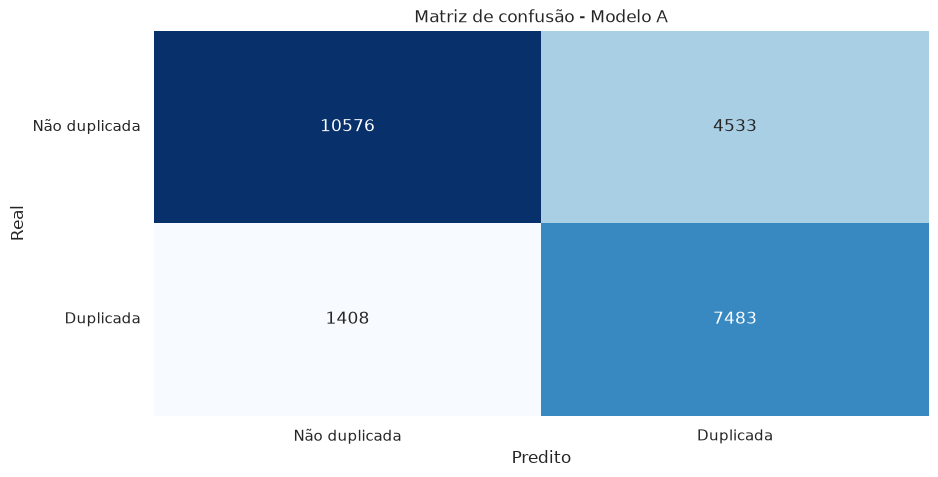

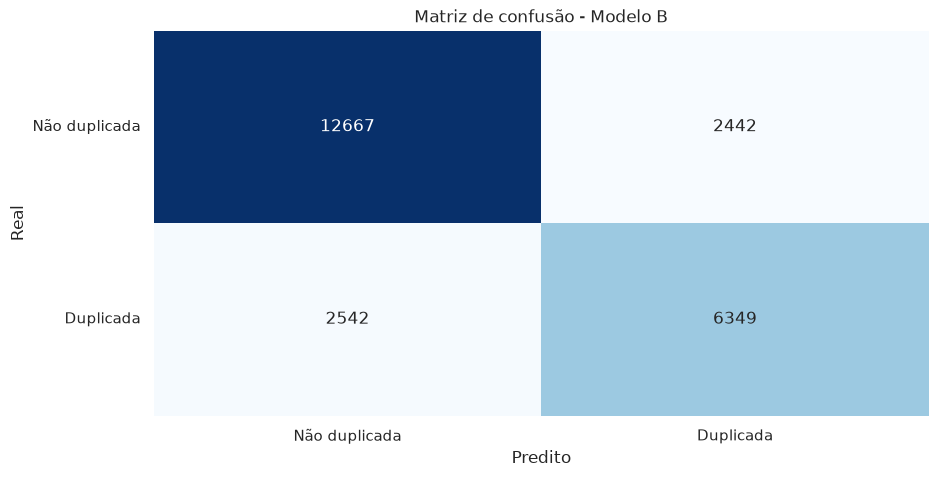

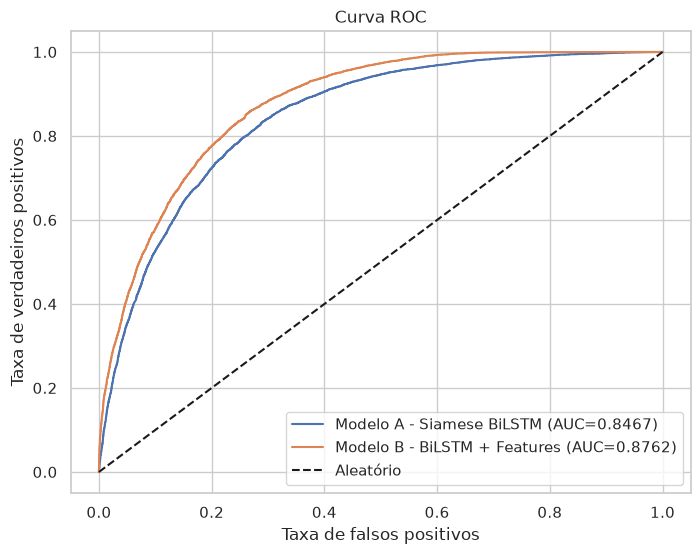

In [21]:
def plot_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, title: str) -> None:
    """Plota matriz de confusão com rótulos interpretáveis."""
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(title)
    plt.xlabel("Predito")
    plt.ylabel("Real")
    plt.xticks([0.5, 1.5], ["Não duplicada", "Duplicada"])
    plt.yticks([0.5, 1.5], ["Não duplicada", "Duplicada"], rotation=0)
    plt.show()


def plot_roc_curves(results: List[dict], y_true: np.ndarray) -> None:
    """Plota curvas ROC para uma lista de resultados de modelos."""
    plt.figure(figsize=(8, 6))
    for result in results:
        fpr, tpr, _ = roc_curve(y_true, result["y_proba"])
        plt.plot(fpr, tpr, label=f"{result['modelo']} (AUC={result['roc_auc']:.4f})")

    plt.plot([0, 1], [0, 1], "k--", label="Aleatório")
    plt.xlabel("Taxa de falsos positivos")
    plt.ylabel("Taxa de verdadeiros positivos")
    plt.title("Curva ROC")
    plt.legend()
    plt.show()


plot_confusion_matrix(y_valid, results_a["y_pred"], "Matriz de confusão - Modelo A")
plot_confusion_matrix(y_valid, results_b["y_pred"], "Matriz de confusão - Modelo B")
plot_roc_curves([results_a, results_b], y_valid)

## 14. Comparação dos modelos

A tabela abaixo resume os dois experimentos. Como a competição é avaliada por Log Loss, o melhor modelo para submissão deve priorizar menor `log_loss`; em caso de empate, ROC AUC e F1 ajudam a interpretar a qualidade geral.

In [22]:
metric_columns = ["accuracy", "precision", "recall", "f1", "roc_auc", "log_loss"]
comparison_sorted = comparison_df.sort_values("log_loss", ascending=True).reset_index(drop=True)
best_model_name = comparison_sorted.loc[0, "modelo"]

display(comparison_sorted.style.format({metric: "{:.4f}" for metric in metric_columns}))
print(f"Melhor modelo pela métrica oficial Log Loss: {best_model_name}")

,modelo,accuracy,precision,recall,f1,roc_auc,log_loss
0,Modelo B - BiLSTM + Features,0.7923,0.7222,0.7141,0.7181,0.8762,0.4179
1,Modelo A - Siamese BiLSTM,0.7525,0.6228,0.8416,0.7158,0.8467,0.5065


Melhor modelo pela métrica oficial Log Loss: Modelo B - BiLSTM + Features


## 15. Geração da submission para o Kaggle

O arquivo de submissão deve conter duas colunas:

- `test_id`
- `is_duplicate`, com a probabilidade prevista de duplicidade.

O código seleciona automaticamente o modelo com menor Log Loss na validação e gera `submission.csv`.

In [24]:
def predict_test_probabilities(best_model_name: str) -> np.ndarray:
    """Prediz probabilidades no teste usando o melhor modelo de validação."""
    if best_model_name == "Modelo B - BiLSTM + Features":
        probabilities = model_b.predict(
            [X_test_q1, X_test_q2, X_test_features],
            batch_size=CONFIG["batch_size"],
        ).ravel()
    else:
        probabilities = model_a.predict(
            [X_test_q1, X_test_q2],
            batch_size=CONFIG["batch_size"],
        ).ravel()

    return np.clip(probabilities, 1e-7, 1 - 1e-7)


test_probabilities = predict_test_probabilities(best_model_name)

submission_df = pd.DataFrame({
    "test_id": test_clean["test_id"].values,
    "is_duplicate": test_probabilities,
})

submission_path = Path("submission.csv")
submission_df.to_csv(submission_path, index=False)

print(f"Arquivo salvo em: {submission_path.resolve()}")
display(submission_df.head())

6960/6960 ━━━━━━━━━━━━━━━━━━━━ 225s 32ms/step
Arquivo salvo em: /home/emanuel-pc/Documentos/Projetos/TP02-IC-Quora-Question-Pairs/submission.csv


,test_id,is_duplicate
0,0,0.040528
1,1,0.316667
2,2,0.298525
3,3,0.001593
4,4,0.638332


In [ ]:
test_predictions_df = pd.DataFrame(
    {
        "test_id": test_clean["test_id"].astype(str).values,
        "is_duplicate": test_probabilities,
    }
)

# Consolidando test_id e reindexando usando o sample_submission esperado pelo Kaggle.
test_predictions_df = (
    test_predictions_df.groupby("test_id", as_index=False, sort=False)["is_duplicate"].mean()
)

sample_submission_keys = sample_submission_df[["test_id"]].copy()
sample_submission_keys["test_id"] = sample_submission_keys["test_id"].astype(str)

submission_df = sample_submission_keys.merge(test_predictions_df, on="test_id", how="left")

if submission_df["is_duplicate"].isna().any():
    missing_ids = submission_df.loc[submission_df["is_duplicate"].isna(), "test_id"].head(10).tolist()
    raise ValueError(f"Alguns test_id do sample_submission ficaram sem previsão: {missing_ids}")

submission_df["test_id"] = pd.to_numeric(submission_df["test_id"], errors="raise").astype("int64")

submission_path = Path("submission.csv")
submission_df.to_csv(submission_path, index=False)

print(f"Arquivo salvo em: {submission_path.resolve()}")
display(submission_df.head())

## 16. Conclusão

Neste trabalho foi desenvolvido um pipeline completo para classificação de pares de perguntas duplicadas do Quora. O Modelo A usa uma arquitetura Siamese BiLSTM, adequada para comparar duas sequências textuais com pesos compartilhados. O Modelo B propõe uma extensão original ao combinar a representação neural com atributos manuais de similaridade lexical e TF-IDF.

A comparação quantitativa permite verificar se as features manuais melhoram a métrica oficial da competição, Log Loss, e também métricas complementares como F1 e ROC AUC. Em geral, espera-se que o Modelo B seja mais robusto quando a sobreposição de palavras, números e estrutura das perguntas fornece sinais importantes de duplicidade.

Possíveis melhorias futuras incluem uso de embeddings pré-treinados, ajuste de limiar de decisão, validação cruzada, Transformers como BERT e calibração probabilística para reduzir ainda mais o Log Loss.